# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Rayhan Lutfi Hakim | 50504251043 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [99]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns   
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [100]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv('Mall_Customers.csv')

print('5 baris pertama:\n',df.head())
print('jumlah baris dan kolom:\n',df.shape)
print('Tipe data:\n', df.info())
print('Deskripsi:\n', df.describe())
print('Jumlah missing value:', df.isnull().sum().sum())
print('Jumlah data duplikat:', df.duplicated().sum())


5 baris pertama:
    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
jumlah baris dan kolom:
 (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
Tipe data:
 None
Deskripsi

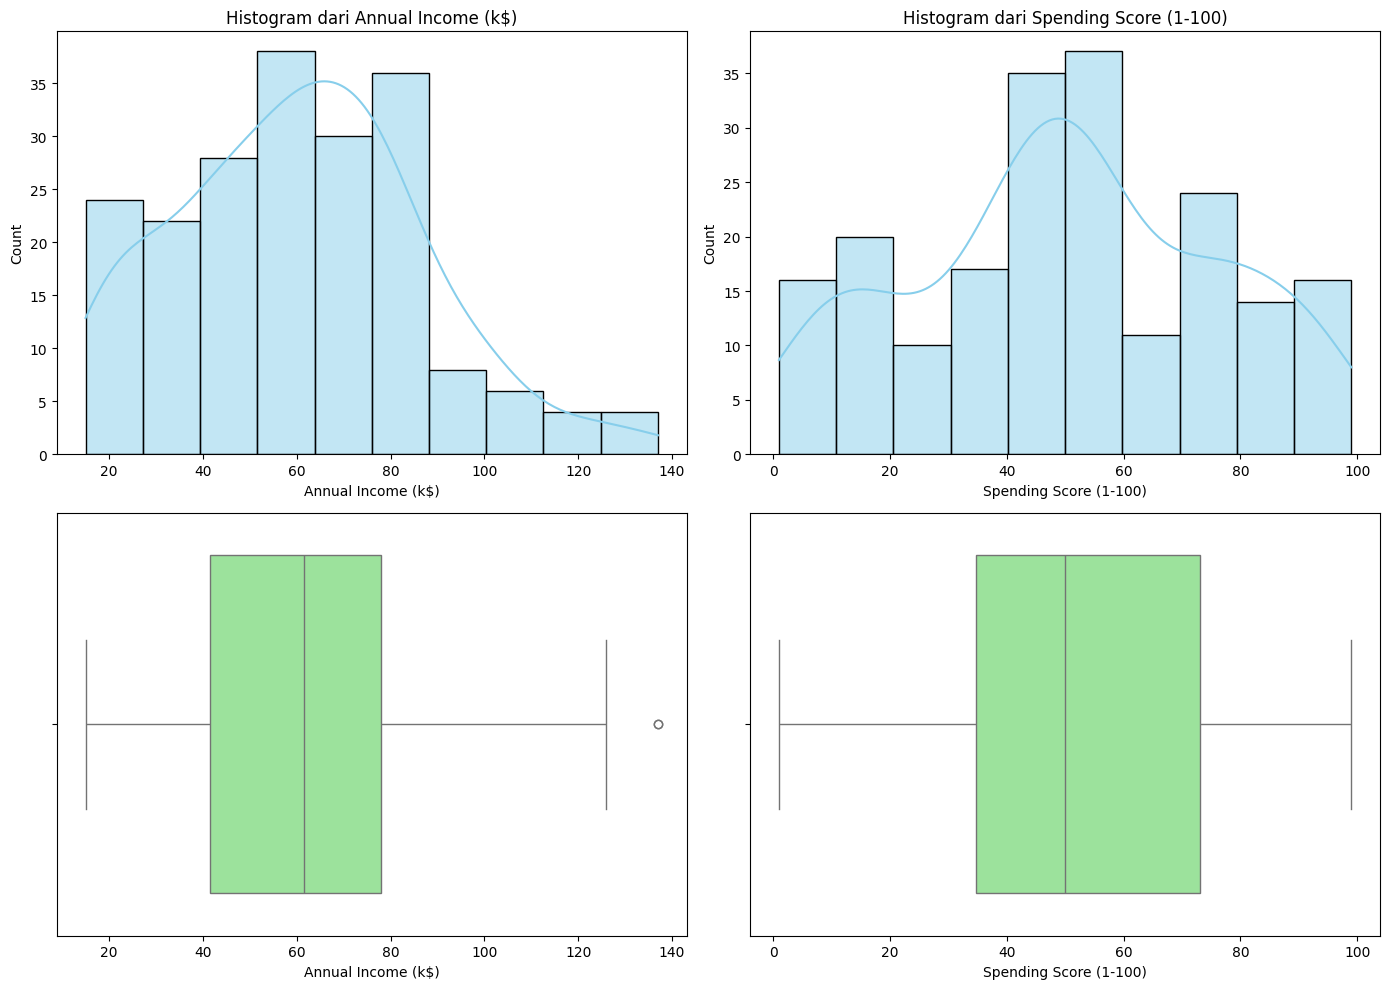

In [101]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(
    df["Annual Income (k$)"],
    kde=True,
    ax=axes[0,0],
    color="skyblue",
    bins=10,
)
axes[0,0].set_title("Histogram dari Annual Income (k$)")
axes[0,0].set_xlabel("Annual Income (k$)")

sns.histplot(
    df["Spending Score (1-100)"],
    kde=True,
    ax=axes[0,1],
    color="skyblue",
    bins=10,
)
axes[0,1].set_title("Histogram dari Spending Score (1-100)")
axes[0,1].set_xlabel("Spending Score (1-100)")

sns.boxplot(x=df["Annual Income (k$)"], ax=axes[1,0], color="lightgreen")
sns.boxplot(x=df["Spending Score (1-100)"], ax=axes[1,1], color="lightgreen")

plt.tight_layout()
plt.show()

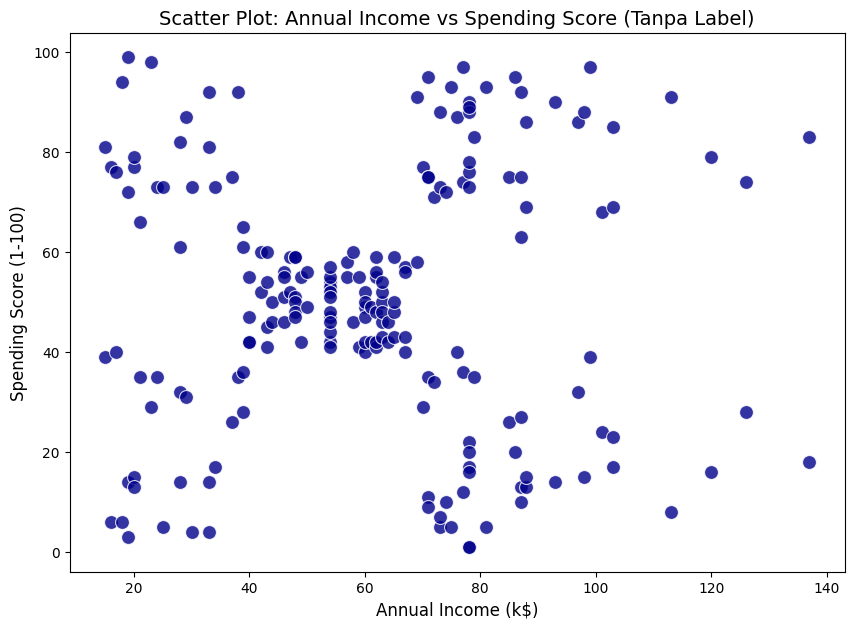

In [102]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    data=df,
    s=100,
    color="darkblue",
    alpha=0.8,
)

plt.title(
    "Scatter Plot: Annual Income vs Spending Score (Tanpa Label)", fontsize=14
)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)

plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

## 1. Tidak ada sama sekali
## 2. Pendapatan: Memiliki rentang yang tidak seimbang terutama dari pendapatan menengah ke pendapatan tinggi, terlihat sedikit sekali orang yang memiliki pendapatan tinggi namun sedang di pendapatan rendah dan tinggi di pendapatan sedang. 
## Spending score: Memiliki rentang yang normal, dari grafik pengeluaran tertinggi berada di rata rata (skor 40-60) dan pengeluaran rendah serta tinggi memiliki rentang yang tidak jauh.
## 3.Iya beberapa memiliki kelompok yang terpisah

# 2. Preprocessing

In [103]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

df = df.drop(columns=['CustomerID'])
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
print(X)

     Annual Income (k$)  Spending Score (1-100)
0                    15                      39
1                    15                      81
2                    16                       6
3                    16                      77
4                    17                      40
..                  ...                     ...
195                 120                      79
196                 126                      28
197                 126                      74
198                 137                      18
199                 137                      83

[200 rows x 2 columns]


In [104]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
print(X_scaled.head())
print(X_scaled.describe())


   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980
       Annual Income (k$)  Spending Score (1-100)
count        2.000000e+02            2.000000e+02
mean        -2.131628e-16           -1.465494e-16
std          1.002509e+00            1.002509e+00
min         -1.738999e+00           -1.910021e+00
25%         -7.275093e-01           -5.997931e-01
50%          3.587926e-02           -7.764312e-03
75%          6.656748e-01            8.851316e-01
max          2.917671e+00            1.894492e+00


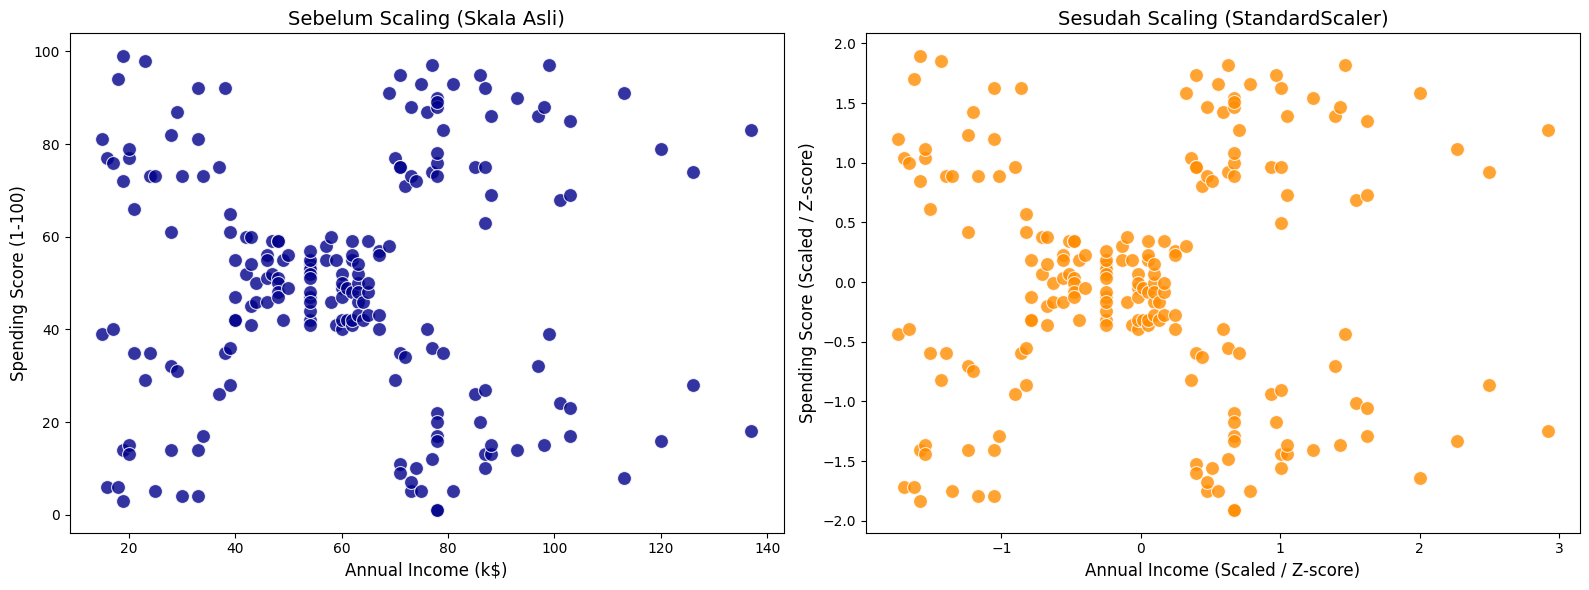

Scaling penting karena perbedaan rentang nilai antar fitur dapat menyebabkan fitur dengan angka besar mendominasi seluruh perhitungan jarak. 


In [105]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatter Plot SEBELUM Scaling
sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    data=X, 
    s=100,
    color="darkblue",
    alpha=0.8,
    ax=axes[0],
)
axes[0].set_title("Sebelum Scaling (Skala Asli)", fontsize=14)
axes[0].set_xlabel("Annual Income (k$)", fontsize=12)
axes[0].set_ylabel("Spending Score (1-100)", fontsize=12)

# 2. Scatter Plot SESUDAH Scaling
sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    data=X_scaled,  
    s=100,
    color="darkorange",
    alpha=0.8,
    ax=axes[1],
)
axes[1].set_title("Sesudah Scaling (StandardScaler)", fontsize=14)
axes[1].set_xlabel("Annual Income (Scaled / Z-score)", fontsize=12)
axes[1].set_ylabel("Spending Score (Scaled / Z-score)", fontsize=12)

plt.tight_layout()
plt.show()
print("Scaling penting karena perbedaan rentang nilai antar fitur dapat menyebabkan fitur dengan angka besar mendominasi seluruh perhitungan jarak. ")


**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

## Karena `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Pemilihan 2 fitur annual income dan spending score dilakukan karena kombinasi keduanya mampu memberikan gambaran langsung tentang daya beli (kemampuan) dan perilaku belanja (kemauan) konsumen.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [106]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.365, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)


In [107]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

print("Jumlah anggota per label (-1 = noise):")
print(pd.Series(labels_dbscan).value_counts().sort_index())

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = int((labels_dbscan == -1).sum())
print("\nJumlah cluster (tanpa noise):", n_clusters_dbscan)
print("Jumlah noise:", n_noise_dbscan)


Jumlah anggota per label (-1 = noise):
-1     21
 0    105
 1     12
 2      7
 3     32
 4     23
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 5
Jumlah noise: 21


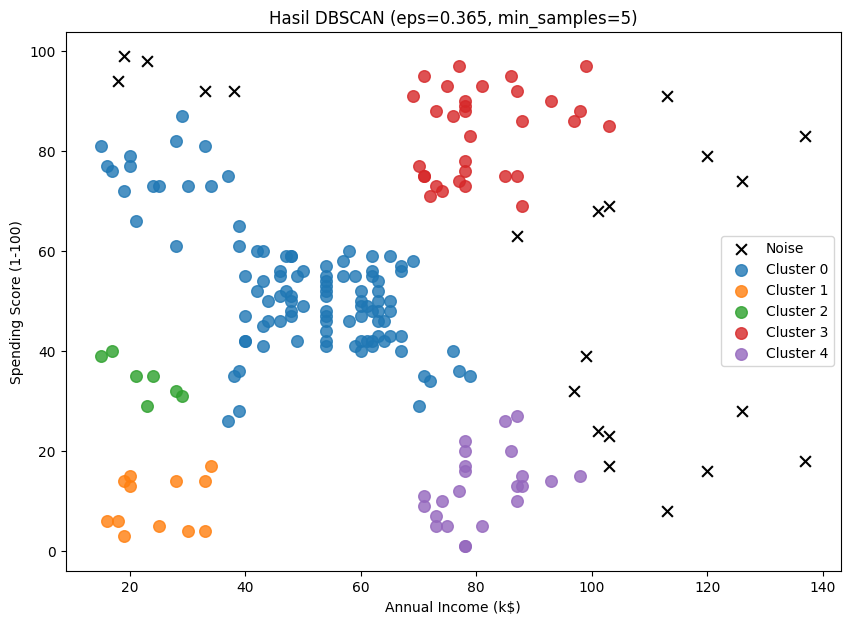

In [108]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

plt.figure(figsize=(10, 7))
for lab in sorted(set(labels_dbscan)):
    mask = labels_dbscan == lab
    if lab == -1:
        plt.scatter(X.loc[mask, "Annual Income (k$)"], X.loc[mask, "Spending Score (1-100)"],
                    c="black", marker="x", s=60, label="Noise")
    else:
        plt.scatter(X.loc[mask, "Annual Income (k$)"], X.loc[mask, "Spending Score (1-100)"],
                    s=70, alpha=0.8, label=f"Cluster {lab}")
plt.title("Hasil DBSCAN (eps=0.365, min_samples=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()


In [109]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

eps_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]
min_samples_list = [3, 5, 8, 10]

rows = []
for eps in eps_list:
    for ms in min_samples_list:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        mask = lab != -1
        # silhouette hanya valid jika ada >= 2 cluster pada titik non-noise
        if n_cl >= 2 and mask.sum() > n_cl:
            sil = silhouette_score(X_scaled[mask], lab[mask])
        else:
            sil = np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_cluster": n_cl,
                     "n_noise": n_noise, "silhouette": sil})

dbscan_summary = pd.DataFrame(rows)
dbscan_summary


,eps,min_samples,n_cluster,n_noise,silhouette
0,0.1,3,14,121,0.561332
1,0.1,5,4,166,0.563278
2,0.1,8,0,200,NaN
3,0.1,10,0,200,NaN
4,0.2,3,13,44,0.469713
5,0.2,5,7,77,0.585613
6,0.2,8,2,116,0.602745
7,0.2,10,1,129,NaN
8,0.3,3,9,14,0.472040
9,0.3,5,7,35,0.524328


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

## 1. Jika eps dinaikkan maka jangkauan tetangga akan makin luas, biasanya cluster semakin sedikit dan noise juga berkurang karena semakin banyak yang dianggap anggota.
## 2. Berpengaruh langsung pada densitas (kepadatan) cluster dan sensitivitas terhadap noise.
## 3. Ada, pada eps 0.7 ke atas dan min_samples berapapun akan menghasilkan 1 cluster saja dan pada eps kecil serta min_samples berapapun akan menghasilkan noise yang begitu banyak.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [110]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)


In [111]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

print("Jumlah anggota per cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index())
print("\nJumlah cluster:", len(set(labels_birch)))
print("Jumlah subcluster di tree:", len(birch.subcluster_centers_))


Jumlah anggota per cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster: 5
Jumlah subcluster di tree: 10


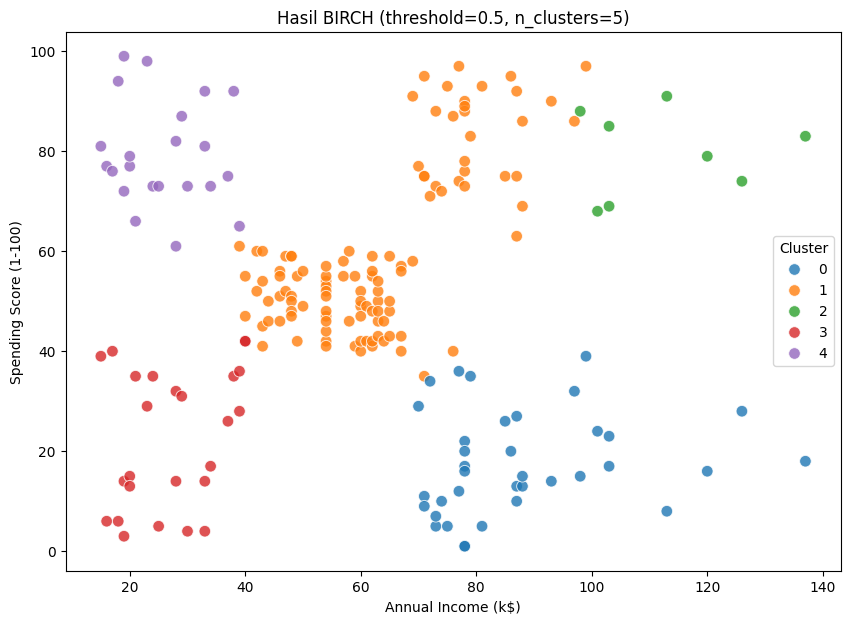

In [112]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X["Annual Income (k$)"], y=X["Spending Score (1-100)"],
                hue=labels_birch, palette="tab10", s=70, alpha=0.8)
plt.title("Hasil BIRCH (threshold=0.5, n_clusters=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()


In [113]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

# Bagian 1: variasi threshold, n_clusters tetap 5
rows = []
for th in [0.3, 0.5, 0.7, 1.0]:
    b = Birch(threshold=th, n_clusters=5)
    lab = b.fit_predict(X_scaled)
    n_cl = len(set(lab))
    sil = silhouette_score(X_scaled, lab) if n_cl >= 2 else np.nan
    rows.append({"threshold": th, "n_subcluster": len(b.subcluster_centers_),
                 "n_cluster": n_cl, "silhouette": sil})
print("Variasi threshold (n_clusters=5):")
display(pd.DataFrame(rows))

# Bagian 2: variasi n_clusters, threshold tetap 0.5
rows = []
for nc in [None, 3, 4, 5, 6, 7]:
    b = Birch(threshold=0.5, n_clusters=nc)
    lab = b.fit_predict(X_scaled)
    n_cl = len(set(lab))
    sil = silhouette_score(X_scaled, lab) if n_cl >= 2 else np.nan
    rows.append({"n_clusters (param)": nc, "n_cluster (hasil)": n_cl, "silhouette": sil})
print("\nVariasi n_clusters (threshold=0.5):")
display(pd.DataFrame(rows))


Variasi threshold (n_clusters=5):


d:\miniconda\envs\satria_data\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_subcluster,n_cluster,silhouette
0,0.3,23,5,0.478062
1,0.5,10,5,0.414450
2,0.7,6,5,0.420676
3,1.0,4,4,0.388557



Variasi n_clusters (threshold=0.5):


,n_clusters (param),n_cluster (hasil),silhouette
0,NaN,10,0.477382
1,3.0,3,0.338191
2,4.0,4,0.351794
3,5.0,5,0.414450
4,6.0,6,0.389768
5,7.0,7,0.521745


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

## 1. Cluster semakin mengecil.
## 2. Jika DBSCAN terdapat min_samples yang menentukan jumlah minimal tetangga pada suatu eps, jika tidak dalam radius tersebut maka akan dianggap noise. Jika BIRCH memiliki treshold, jika titik tersebut terlalu jauh dan melewati threshold, akan membuat sub-cluster baru untuk titik tersebut.
## 3. Tidak sama sekali.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [114]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)


In [115]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

print("Jumlah anggota per cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"P(cluster {i})" for i in range(proba.shape[1])]).round(3)
print("\nProbabilitas keanggotaan (10 baris pertama):")
display(proba_df.head(10))

# Titik yang tidak pasti: probabilitas tertinggi < 0.8
max_proba = proba.max(axis=1)
uncertain = max_proba < 0.8
print(f"\nJumlah titik dengan probabilitas tertinggi < 0.8: {uncertain.sum()} dari {len(X)}")
display(pd.concat([X[uncertain], proba_df[uncertain]], axis=1).head(10))


Jumlah anggota per cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

Probabilitas keanggotaan (10 baris pertama):


,P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4)
0,0.000,0.0,0.001,0.0,0.999
1,0.000,0.0,1.000,0.0,0.000
2,0.000,0.0,0.000,0.0,1.000
3,0.000,0.0,1.000,0.0,0.000
4,0.000,0.0,0.002,0.0,0.998
5,0.000,0.0,1.000,0.0,0.000
6,0.000,0.0,0.000,0.0,1.000
7,0.000,0.0,1.000,0.0,0.000
8,0.000,0.0,0.000,0.0,1.000
9,0.001,0.0,0.998,0.0,0.000



Jumlah titik dengan probabilitas tertinggi < 0.8: 6 dari 200


,Annual Income (k$),Spending Score (1-100),P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4)
27,28,61,0.279,0.0,0.675,0.000,0.046
48,40,42,0.611,0.0,0.000,0.000,0.388
49,40,42,0.611,0.0,0.000,0.000,0.388
55,43,41,0.796,0.0,0.000,0.000,0.204
124,70,29,0.497,0.0,0.000,0.503,0.000
160,79,35,0.772,0.0,0.000,0.228,0.000


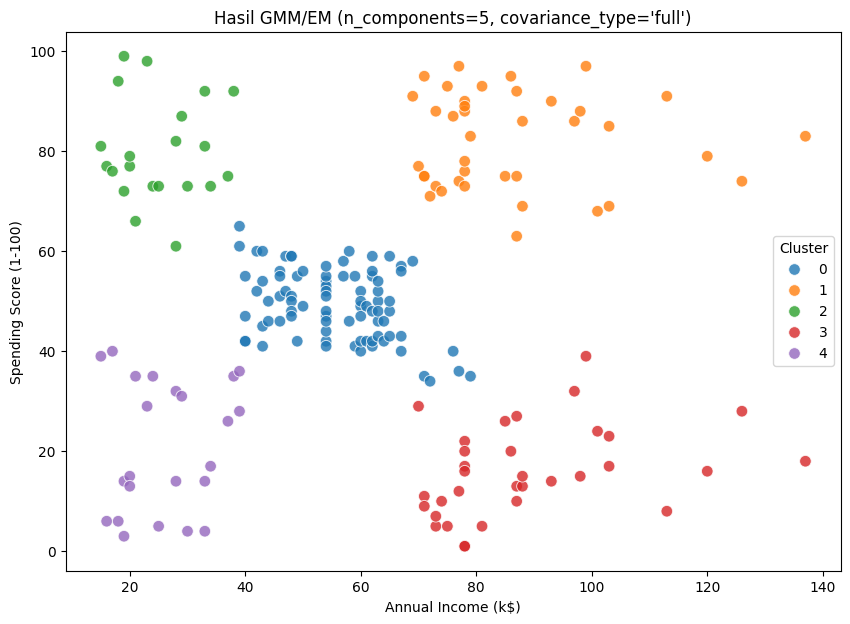

In [116]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

plt.figure(figsize=(10, 7))
sns.scatterplot(x=X["Annual Income (k$)"], y=X["Spending Score (1-100)"],
                hue=labels_gmm, palette="tab10", s=70, alpha=0.8)
plt.title("Hasil GMM/EM (n_components=5, covariance_type='full')")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()


,n_components,silhouette,BIC
0,2,0.379082,1153.904655
1,3,0.430190,1151.718274
2,4,0.413392,1103.790149
3,5,0.553689,1058.652252
4,6,0.516982,1074.682807
5,7,0.509057,1087.328517
6,8,0.430210,1102.370701


Silhouette tertinggi di n_components = 5
BIC terendah di n_components = 5


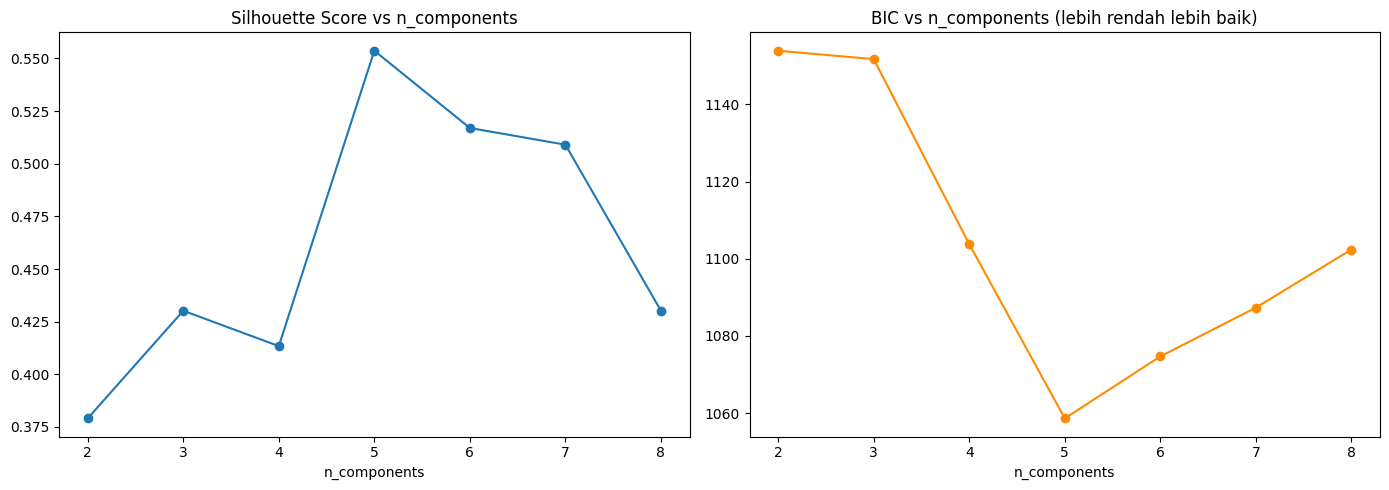

In [117]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({"n_components": k,
                 "silhouette": silhouette_score(X_scaled, lab),
                 "BIC": g.bic(X_scaled)})
gmm_summary = pd.DataFrame(rows)
display(gmm_summary)

print("Silhouette tertinggi di n_components =", gmm_summary.loc[gmm_summary["silhouette"].idxmax(), "n_components"])
print("BIC terendah di n_components =", gmm_summary.loc[gmm_summary["BIC"].idxmin(), "n_components"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(gmm_summary["n_components"], gmm_summary["silhouette"], marker="o")
axes[0].set_title("Silhouette Score vs n_components")
axes[0].set_xlabel("n_components")
axes[1].plot(gmm_summary["n_components"], gmm_summary["BIC"], marker="o", color="darkorange")
axes[1].set_title("BIC vs n_components (lebih rendah lebih baik)")
axes[1].set_xlabel("n_components")
plt.tight_layout()
plt.show()


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

## 1. tingkat kepercayaan atau derajat kepemilikan suatu data terhadap masing-masing cluster yang ada.
## 2. Nilai silhoutte dan BIC berubah.
## 3. arsitektur matematis GMM didasarkan pada asumsi jumlah distribusi Gaussian yang menyusun data tersebut.
## 4. Iya

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [118]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluate_clustering(X_data, labels, is_dbscan=False):
    """Mengembalikan dict berisi jumlah cluster, noise, dan 3 metrik internal."""
    X_arr = np.asarray(X_data)
    labels = np.asarray(labels)
    n_noise = int((labels == -1).sum()) if is_dbscan else 0

    # DBSCAN: buang noise sebelum hitung metrik
    if is_dbscan:
        mask = labels != -1
        X_arr, labels = X_arr[mask], labels[mask]

    n_clusters = len(set(labels))
    result = {"n_cluster": n_clusters, "n_noise": n_noise,
              "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}

    # Metrik valid jika >= 2 cluster dan n_cluster < jumlah titik
    if n_clusters >= 2 and n_clusters < len(X_arr):
        result["silhouette"] = silhouette_score(X_arr, labels)
        result["davies_bouldin"] = davies_bouldin_score(X_arr, labels)
        result["calinski_harabasz"] = calinski_harabasz_score(X_arr, labels)
    return result


In [124]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

best_eps, best_min_samples = 0.4, 8
best_threshold, best_n_clusters = 0.5, 5
best_n_components = 5

labels_dbscan_best = DBSCAN(eps=best_eps, min_samples=best_min_samples).fit_predict(X_scaled)
labels_birch_best = Birch(threshold=best_threshold, n_clusters=best_n_clusters).fit_predict(X_scaled)
labels_gmm_best = GaussianMixture(n_components=best_n_components, covariance_type="full",
                                  random_state=42).fit(X_scaled).predict(X_scaled)

comparison = pd.DataFrame([
    {"model": f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})",
     **evaluate_clustering(X_scaled, labels_dbscan_best, is_dbscan=True)},
    {"model": f"BIRCH (threshold={best_threshold}, n_clusters={best_n_clusters})",
     **evaluate_clustering(X_scaled, labels_birch_best)},
    {"model": f"GMM (n_components={best_n_components})",
     **evaluate_clustering(X_scaled, labels_gmm_best)},
]).round(3)
comparison


,model,n_cluster,n_noise,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.4, min_samples=8)",5,25,0.549,0.501,222.065
1,"BIRCH (threshold=0.5, n_clusters=5)",5,0,0.414,0.698,125.949
2,GMM (n_components=5),5,0,0.554,0.576,244.940


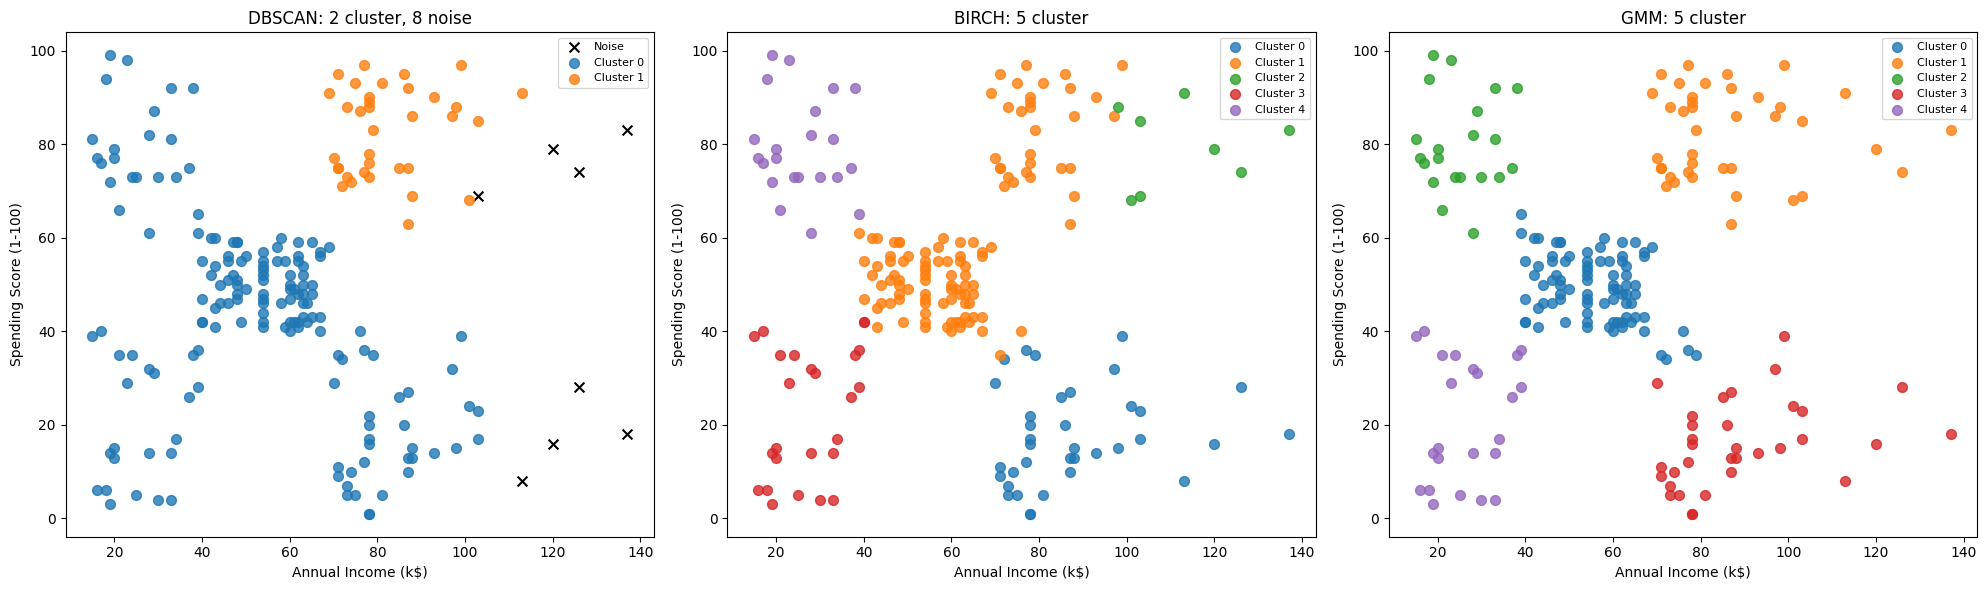

In [120]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

def plot_labels(ax, labels, title):
    for lab in sorted(set(labels)):
        mask = labels == lab
        if lab == -1:
            ax.scatter(X.loc[mask, "Annual Income (k$)"], X.loc[mask, "Spending Score (1-100)"],
                       c="black", marker="x", s=50, label="Noise")
        else:
            ax.scatter(X.loc[mask, "Annual Income (k$)"], X.loc[mask, "Spending Score (1-100)"],
                       s=50, alpha=0.8, label=f"Cluster {lab}")
    ax.set_title(title)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.legend(fontsize=8)

n_cl_db = len(set(labels_dbscan_best)) - (1 if -1 in labels_dbscan_best else 0)
n_noise_db = int((labels_dbscan_best == -1).sum())

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
plot_labels(axes[0], labels_dbscan_best, f"DBSCAN: {n_cl_db} cluster, {n_noise_db} noise")
plot_labels(axes[1], labels_birch_best, f"BIRCH: {len(set(labels_birch_best))} cluster")
plot_labels(axes[2], labels_gmm_best, f"GMM: {len(set(labels_gmm_best))} cluster")
plt.tight_layout()
plt.show()


In [121]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

def profile_clusters(labels, name):
    tmp = X.copy()
    tmp["cluster"] = labels
    prof = tmp.groupby("cluster").agg(
        jumlah=("cluster", "size"),
        income_mean=("Annual Income (k$)", "mean"),
        income_median=("Annual Income (k$)", "median"),
        spending_mean=("Spending Score (1-100)", "mean"),
        spending_median=("Spending Score (1-100)", "median"),
    ).round(1)
    print(f"=== Profil cluster {name} ===")
    display(prof)

# DBSCAN: label -1 (noise) otomatis muncul sebagai baris terpisah
profile_clusters(labels_dbscan_best, "DBSCAN (cluster -1 = noise)")
profile_clusters(labels_birch_best, "BIRCH")
profile_clusters(labels_gmm_best, "GMM")


=== Profil cluster DBSCAN (cluster -1 = noise) ===


,jumlah,income_mean,income_median,spending_mean,spending_median
cluster,,,,,
-1,8,122.8,123.0,46.9,48.5
0,157,52.5,54.0,43.1,46.0
1,35,82.5,78.0,82.8,86.0


=== Profil cluster BIRCH ===


,jumlah,income_mean,income_median,spending_mean,spending_median
cluster,,,,,
0,36,87.8,83.0,17.6,16.0
1,109,62.4,62.0,59.3,55.0
2,8,112.6,108.0,79.6,81.0
3,25,27.4,28.0,22.6,26.0
4,22,25.7,24.5,79.4,77.0


=== Profil cluster GMM ===


,jumlah,income_mean,income_median,spending_mean,spending_median
cluster,,,,,
0,84,55.6,55.5,49.4,49.5
1,39,86.5,79.0,82.1,83.0
2,21,25.1,24.0,80.0,77.0
3,33,88.8,86.0,16.0,15.0
4,23,26.3,25.0,20.9,17.0


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Tidak | Iya |
| Dapat memberi label noise secara eksplisit? | Iya | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | eps dan min_samples | Threshold dan n_clusters | n_components |
| Bentuk cluster yang dapat dimodelkan | bentuk bebas | cenderung bulat | elips |
| Kelebihan | Tidak perlu tentukan jumlah cluster, bisa mendeteksi noise, bentuk cluster fleksibel | Cepat dan hemat memori karena meringkas data ke tree, cocok untuk data besar | Memberi probabilitas keanggotaan (soft clustering), mampu memodelkan cluster elips, BIC membantu memilih jumlah komponen |
| Kekurangan | Sensitif terhadap eps dan min_samples, sulit jika kepadatan antar cluster berbeda | Kurang cocok untuk cluster non-bulat, bergantung pada threshold, tidak melabeli noise | Jumlah komponen harus ditentukan, mengasumsikan data Gaussian, hasil bisa bergantung inisialisasi |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

1. Karena DBSCAN, BIRCH, dan GMM semuanya bergantung pada jarak atau sebaran data.
2. eps sangat kecil membuat hampir semua titik jadi noise, eps sangat besar membuat satu cluster raksasa.
3. Threshold untuk mengatur pembentukan tree (semakin besar semakin jauh titik boleh digabung ke satu subcluster). n_cluster mengatur subcluster digabung lagi sampai tersisa sejumlah itu.
4. Makna probabilitas keanggotaan GMM menyatakan seberapa besar kemungkinan suatu titik berasal dari tiap komponen Gaussian. EM bekerja dengan dua langkah berulang: E-step: hitung probabilitas tiap titik milik tiap komponen. dan M-step: perbarui parameter tiap komponen, dengan titik yang punya probabilitas lebih besar berkontribusi lebih besar ke komponen itu.
5. GMM dan BIRCH, tiap titik punya cluster, dan profil income/spending-nya bisa langsung dinamai, jadi lebih mudah dipakai untuk segmentasi pelanggan.
6. Tidak, karena setiap matriks menilai hal yang berbeda-beda. Silhouette melihat kedekatan ke cluster sendiri vs cluster lain. Davies-Bouldin melihat rasio sebaran dalam cluster terhadap jarak antar cluster. Calinski-Harabasz membandingkan varians antar cluster dengan varians dalam cluster.
7. BIRCH dan GMM sama-sama membentuk lima segmen berdasarkan median income dan spending score, yaitu **hemat** (income rendah, spending rendah), **boros relatif terhadap pendapatan** (income rendah, spending tinggi), **pelanggan standar** (income sedang, spending sedang), **kaya tapi hemat** (income tinggi, spending rendah), dan **premium** (income tinggi, spending tinggi), sedangkan DBSCAN hanya membentuk dua cluster (satu kelompok besar campuran berisi 157 pelanggan dan satu kelompok premium) ditambah 8 noise berpendapatan sangat tinggi sehingga kurang cocok untuk segmentasi.
8. Dua fitur mengabaikan hal lain yang relevan seperti usia dan gender, jadi segmentasinya dangkal.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

1. GMM dan BIRCH.
2. DBSCAN(eps= 5, min_samples=8), karena dengan menghasilkan cluster=5 bisa menghasilkan juga jumlah noise yang kecil. BIRCH(threshold=0.5, n_clusters=5)mengikuti jumlah gerombolan yang terlihat di scatter plot, threshold dipilih dari tabel variasi. GMM(n_components=5), karena bisa menghasilkan BIC yang terendah.
3. DBSCAN membentuk cluster dari kepadatan, menentukan jumlah cluster sendiri, dan menandai noise.
BIRCH meringkas data ke dalam tree subcluster lalu menggabungkannya, efisien tapi cenderung bulat dan tidak punya noise.
GMM memodelkan data sebagai campuran Gaussian lewat EM, menghasilkan probabilitas keanggotaan, tapi butuh jumlah komponen di awal.
4. Membuat k-distance plot untuk memilih eps DBSCAN secara terarah.
Mencoba covariance_type lain (tied, diag, spherical) pada GMM.
Menambahkan fitur Age, dan memakai Gender untuk interpretasi cluster.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)